# Cross-Entropy versus Robust Cross-Entropy

Run the cells from top to bottom in a Python 3 Jupyter kernel. Keep this notebook
beside the project Python modules and install the packages in `requirements.txt`.
The notebook runs both simulations and writes fresh results to a temporary
directory. The full sweep can take a few minutes on CPU.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
from unittest.mock import patch
from io import BytesIO
import json

PROJECT = Path.cwd()
required = ("checks.py", "losses.py", "models.py", "experiment.py", "report_results.py")
missing = [name for name in required if not (PROJECT / name).is_file()]
if missing:
    raise FileNotFoundError(f"Open Jupyter in the project directory. Missing: {', '.join(missing)}")

import experiment as exp
import checks
import report_results as reporting
from losses import cross_entropy, robust_cross_entropy, smoothed_target
from losses import worst_target, logit_gradient

import numpy as np
from IPython.display import Image, Markdown, display
from scipy.stats import t

def show_table(headers, rows):
    header = "| " + " | ".join(headers) + " |"
    separator = "| " + " | ".join("---" for _ in headers) + " |"
    lines = ["| " + " | ".join(map(str, row)) + " |" for row in rows]
    display(Markdown("\n".join([header, separator, *lines])))

print(f"Loaded two simulations and {len(exp.METHODS)} objectives.")

Loaded two simulations and 3 objectives.


## 1. Evaluate the three losses

The example uses observed label $y=0$ and binary radius
$\delta=\rho\tau/\sqrt{2}=0.2$. RobustCE chooses the worst feasible target
at each logit. Label smoothing with $\varepsilon=0.4$ uses the same fixed
class-1 mass, $0.2$, for every row.

In [2]:
p1 = np.array([0.1, 0.4, 0.5, 0.6])
logits = np.log(p1 / (1 - p1))
y = np.zeros_like(p1)
delta, epsilon = 0.20, 0.40

q_star = worst_target(logits, y, delta)
q_smooth = smoothed_target(y, epsilon)
ce = cross_entropy(logits, y)
robust = robust_cross_entropy(logits, y, delta)
smoothed = cross_entropy(logits, q_smooth)
gradient = logit_gradient(logits, q_star)

show_table(["$p_1$", "$q^*$", "CE", "RobustCE", "Smoothed CE", "Robust logit derivative"],
           ([f"{p:.1f}", f"{q:.1f}", f"{c:.4f}", f"{r:.4f}", f"{ls:.4f}", f"{g:+.4f}"]
            for p, q, c, r, ls, g in zip(p1, q_star, ce, robust, smoothed, gradient)))

| $p_1$ | $q^*$ | CE | RobustCE | Smoothed CE | Robust logit derivative |
| --- | --- | --- | --- | --- | --- |
| 0.1 | 0.2 | 0.1054 | 0.5448 | 0.5448 | -0.1000 |
| 0.4 | 0.2 | 0.5108 | 0.5919 | 0.5919 | +0.2000 |
| 0.5 | 0.0 | 0.6931 | 0.6931 | 0.6931 | +0.5000 |
| 0.6 | 0.0 | 0.9163 | 0.9163 | 0.8352 | +0.6000 |

## 2. Run the numerical checks

The checks cover zero radius, the nominal-loss lower bound, direct interval
search, extreme logits, and derivative behavior at and away from ties.

In [3]:
checks.main()

p1, CE, RobustCE, q*:
[[0.1        0.10536052 0.54480543 0.2       ]
 [0.4        0.51082562 0.59191865 0.2       ]
 [0.6        0.91629073 0.91629073 0.        ]]
Maximum dense-search error over 175 cases: 8.882e-16
All loss and derivative checks passed.


## 3. Inspect the simulation inputs

Seed 101 is a tuning seed. Inspect its clean training and validation splits
and the initial model sizes. Each split is balanced before any label flips.

In [4]:
split_rows = []
for simulation in exp.SIMULATIONS:
    train, valid, test, initial, _ = exp.prepare(simulation, exp.TUNING_SEEDS[0])
    assert test is None
    split_rows.append([simulation, len(train.y), len(valid.y),
                       int(train.y.sum()), int(valid.y.sum()),
                       sum(array.size for array in initial)])
show_table(["Simulation", "Train size", "Validation size", "Train class 1",
            "Validation class 1", "Parameters"], split_rows)

| Simulation | Train size | Validation size | Train class 1 | Validation class 1 | Parameters |
| --- | --- | --- | --- | --- | --- |
| gaussian | 512 | 512 | 256 | 256 | 3 |
| semicircles | 512 | 512 | 256 | 256 | 33 |

## 4. Tune on clean validation data and run held-out evaluation

The project runner calls the same training functions for both models. It searches
learning rates and loss strengths on tuning seeds 101–105, freezes the winners,
and then evaluates seeds 201–210 at 0%, 15%, and 30% training-label corruption.
Validation and test labels remain clean. Every model is scored at the common
evaluation radius $0.10$.

In [5]:
scratch = TemporaryDirectory(prefix="robust-ce-notebook-")
run_dir = Path(scratch.name)
with patch.object(exp, "HERE", run_dir):
    exp.main()

result_dir = run_dir / "results"
protocol = json.loads((result_dir / "protocol.json").read_text(encoding="utf-8"))
failures = json.loads((result_dir / "failures.json").read_text(encoding="utf-8"))
with patch.object(reporting, "ROOT", run_dir):
    tuning = reporting.read_csv("tuning.csv")
    testing = reporting.read_csv("evaluation.csv")
    learning = reporting.read_csv("learning.csv")

assert set(protocol["tuning_seeds"]).isdisjoint(protocol["evaluation_seeds"])
expected = len(exp.SIMULATIONS) * len(exp.METHODS) * len(exp.EVALUATION_SEEDS) * len(exp.CORRUPTION)
print(f"Evaluation fits: {len(testing)} / {expected}. Logged failures: {len(failures)}.")
if failures:
    display(failures)

{
  "gaussian": {
    "CE": {
      "method": "CE",
      "rate": 0.01,
      "strength": 0.0
    },
    "RobustCE": {
      "method": "RobustCE",
      "rate": 0.03,
      "strength": 0.1
    },
    "Smoothing": {
      "method": "Smoothing",
      "rate": 0.03,
      "strength": 0.2
    }
  },
  "semicircles": {
    "CE": {
      "method": "CE",
      "rate": 0.03,
      "strength": 0.0
    },
    "RobustCE": {
      "method": "RobustCE",
      "rate": 0.3,
      "strength": 0.1
    },
    "Smoothing": {
      "method": "Smoothing",
      "rate": 0.6,
      "strength": 0.2
    }
  }
}


Completed 1900 tuning runs and 180 evaluation runs. Failures: 0.
Evaluation fits: 180 / 180. Logged failures: 0.


### Selected settings

The initial learning rate is tuned separately for each objective.
Strength is the training radius for RobustCE and epsilon for smoothing.

In [6]:
show_table(["Simulation", "Objective", "Initial rate", "Strength"],
           ([sim, method, f"{values['rate']:g}",
             "—" if method == "CE" else f"{values['strength']:g}"]
            for sim, settings in protocol["settings"].items()
            for method, values in settings.items()))

| Simulation | Objective | Initial rate | Strength |
| --- | --- | --- | --- |
| gaussian | CE | 0.01 | — |
| gaussian | RobustCE | 0.03 | 0.1 |
| gaussian | Smoothing | 0.03 | 0.2 |
| semicircles | CE | 0.03 | — |
| semicircles | RobustCE | 0.3 | 0.1 |
| semicircles | Smoothing | 0.6 | 0.2 |

### Replay one matched fit per method

Use seed 201 and 30% training-label flips. The calls below show how to prepare
data, fit a model, and score the same clean test split. The replay verifies
the corresponding results from the full sweep.

In [7]:
seed = protocol["representative_seed"]
eta = protocol["corruption"][-1]
replay_rows = []
for simulation, model in exp.SIMULATIONS.items():
    train, valid, test, initial, flip_uniforms = exp.prepare(simulation, seed, with_test=True)
    flip_mask = flip_uniforms < eta
    observed = np.where(flip_mask, 1 - train.y, train.y)
    for method, values in protocol["settings"][simulation].items():
        setting = exp.Setting(**values)
        params, seconds, history = exp.fit(model, initial, train, observed, valid, setting,
                                           record=True)
        score = exp.evaluate(model, params, test)
        reference, = reporting.subset(testing, simulation=simulation, seed=seed,
                                      eta=eta, method=method)
        np.testing.assert_allclose(list(score.values()), [reference[key] for key in score],
                                   rtol=1e-12, atol=1e-12)
        replay_rows.append([simulation, method, int(flip_mask.sum()),
                            f"{history[0]['ce']:.4f} → {history[-1]['ce']:.4f}",
                            f"{score['accuracy']:.2%}", f"{score['ce']:.4f}",
                            f"{score['robust_ce']:.4f}", f"{seconds:.3f}"])
show_table(["Simulation", "Objective", "Flips", "Validation CE (first → last)",
            "Test accuracy", "Test CE", "Test RobustCE", "Fit time (s)"], replay_rows)

| Simulation | Objective | Flips | Validation CE (first → last) | Test accuracy | Test CE | Test RobustCE | Fit time (s) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| gaussian | CE | 151 | 0.5556 → 0.4675 | 90.67% | 0.4642 | 0.5245 | 0.036 |
| gaussian | RobustCE | 151 | 0.5556 → 0.5415 | 90.58% | 0.5392 | 0.5761 | 0.035 |
| gaussian | Smoothing | 151 | 0.5556 → 0.5086 | 90.72% | 0.5057 | 0.5523 | 0.025 |
| semicircles | CE | 177 | 0.8310 → 0.4413 | 97.36% | 0.4455 | 0.5068 | 0.076 |
| semicircles | RobustCE | 177 | 0.8310 → 0.5295 | 94.68% | 0.5319 | 0.5700 | 0.085 |
| semicircles | Smoothing | 177 | 0.8310 → 0.4848 | 94.68% | 0.4904 | 0.5393 | 0.069 |

## 5. Summarize held-out performance

Each entry is mean ± sample standard deviation over ten evaluation seeds.
Training times reflect the current machine and load.

In [8]:
def mean_sd(rows, metric):
    mean, sd = reporting.stats(rows, metric)
    scale = 100 if metric == "accuracy" else 1
    digits = 2 if metric == "accuracy" else 3
    return f"{scale * mean:.{digits}f} ± {scale * sd:.{digits}f}"

for simulation in exp.SIMULATIONS:
    display(Markdown(f"**{reporting.TITLES[simulation]}**"))
    summary = []
    for eta in protocol["corruption"]:
        for method in exp.METHODS:
            rows = reporting.subset(testing, simulation=simulation, eta=eta, method=method)
            summary.append([f"{eta:.0%}", method, len(rows),
                            *(mean_sd(rows, key) for key in (*exp.METRICS, "seconds"))])
    show_table(["Flips", "Objective", "n", "Accuracy (%)", "Test CE",
                "Test RobustCE", "Confidence", "Fit time (s)"], summary)

**Gaussian logistic regression**

| Flips | Objective | n | Accuracy (%) | Test CE | Test RobustCE | Confidence | Fit time (s) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0% | CE | 10 | 89.56 ± 3.54 | 0.325 ± 0.122 | 0.490 ± 0.056 | 0.783 ± 0.098 | 0.024 ± 0.005 |
| 0% | RobustCE | 10 | 91.98 ± 0.90 | 0.277 ± 0.010 | 0.439 ± 0.006 | 0.801 ± 0.007 | 0.029 ± 0.005 |
| 0% | Smoothing | 10 | 91.99 ± 0.90 | 0.274 ± 0.010 | 0.439 ± 0.006 | 0.804 ± 0.006 | 0.027 ± 0.010 |
| 15% | CE | 10 | 89.52 ± 4.06 | 0.390 ± 0.106 | 0.493 ± 0.067 | 0.716 ± 0.074 | 0.023 ± 0.004 |
| 15% | RobustCE | 10 | 91.91 ± 0.54 | 0.403 ± 0.019 | 0.486 ± 0.012 | 0.690 ± 0.015 | 0.029 ± 0.007 |
| 15% | Smoothing | 10 | 91.98 ± 0.53 | 0.386 ± 0.017 | 0.477 ± 0.010 | 0.704 ± 0.013 | 0.024 ± 0.008 |
| 30% | CE | 10 | 85.39 ± 12.04 | 0.501 ± 0.071 | 0.553 ± 0.054 | 0.628 ± 0.038 | 0.025 ± 0.009 |
| 30% | RobustCE | 10 | 91.15 ± 0.88 | 0.536 ± 0.019 | 0.574 ± 0.014 | 0.594 ± 0.012 | 0.033 ± 0.008 |
| 30% | Smoothing | 10 | 91.35 ± 0.66 | 0.503 ± 0.017 | 0.550 ± 0.012 | 0.617 ± 0.012 | 0.026 ± 0.008 |

**Semicircle network**

| Flips | Objective | n | Accuracy (%) | Test CE | Test RobustCE | Confidence | Fit time (s) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0% | CE | 10 | 96.21 ± 4.06 | 0.105 ± 0.073 | 0.474 ± 0.034 | 0.935 ± 0.030 | 0.073 ± 0.016 |
| 0% | RobustCE | 10 | 99.88 ± 0.06 | 0.117 ± 0.002 | 0.335 ± 0.001 | 0.891 ± 0.002 | 0.075 ± 0.013 |
| 0% | Smoothing | 10 | 99.82 ± 0.12 | 0.116 ± 0.002 | 0.334 ± 0.002 | 0.892 ± 0.002 | 0.067 ± 0.008 |
| 15% | CE | 10 | 97.29 ± 3.62 | 0.226 ± 0.044 | 0.385 ± 0.030 | 0.813 ± 0.020 | 0.068 ± 0.008 |
| 15% | RobustCE | 10 | 99.47 ± 0.30 | 0.281 ± 0.012 | 0.400 ± 0.006 | 0.760 ± 0.010 | 0.075 ± 0.011 |
| 15% | Smoothing | 10 | 98.91 ± 0.80 | 0.264 ± 0.015 | 0.391 ± 0.009 | 0.774 ± 0.011 | 0.070 ± 0.015 |
| 30% | CE | 10 | 96.17 ± 2.57 | 0.401 ± 0.032 | 0.478 ± 0.021 | 0.679 ± 0.022 | 0.069 ± 0.010 |
| 30% | RobustCE | 10 | 95.67 ± 2.15 | 0.475 ± 0.034 | 0.528 ± 0.025 | 0.629 ± 0.021 | 0.077 ± 0.013 |
| 30% | Smoothing | 10 | 95.62 ± 2.80 | 0.441 ± 0.032 | 0.505 ± 0.024 | 0.654 ± 0.020 | 0.069 ± 0.011 |

### Paired comparisons

Subtract the second method from the first on each matched seed. The intervals
are marginal 95% t intervals. Positive accuracy differences and negative loss
differences favor the first method.

In [9]:
def paired_interval(first, second, metric):
    seeds = sorted(first.keys() & second.keys())
    differences = np.array([first[seed][metric] - second[seed][metric] for seed in seeds])
    if metric == "accuracy":
        differences *= 100
    center = differences.mean()
    margin = t.ppf(0.975, len(seeds) - 1) * differences.std(ddof=1) / np.sqrt(len(seeds))
    digits = 2 if metric == "accuracy" else 4
    return f"{center:+.{digits}f} [{center - margin:+.{digits}f}, {center + margin:+.{digits}f}]"

pairs = (("RobustCE", "CE"), ("Smoothing", "CE"), ("RobustCE", "Smoothing"))
for simulation in exp.SIMULATIONS:
    display(Markdown(f"**{reporting.TITLES[simulation]}**"))
    intervals = []
    for eta in protocol["corruption"]:
        condition = reporting.subset(testing, simulation=simulation, eta=eta)
        by_method = {method: {row["seed"]: row for row in reporting.subset(condition, method=method)}
                     for method in exp.METHODS}
        for first, second in pairs:
            intervals.append([f"{eta:.0%}", f"{first} − {second}",
                              *(paired_interval(by_method[first], by_method[second], metric)
                                for metric in reporting.METRICS)])
    show_table(["Flips", "Contrast", "Accuracy (pp)", "Test CE", "Test RobustCE"], intervals)

**Gaussian logistic regression**

| Flips | Contrast | Accuracy (pp) | Test CE | Test RobustCE |
| --- | --- | --- | --- | --- |
| 0% | RobustCE − CE | +2.42 [+0.19, +4.65] | -0.0484 [-0.1305, +0.0337] | -0.0509 [-0.0903, -0.0116] |
| 0% | Smoothing − CE | +2.43 [+0.20, +4.66] | -0.0515 [-0.1344, +0.0314] | -0.0511 [-0.0905, -0.0116] |
| 0% | RobustCE − Smoothing | -0.01 [-0.05, +0.03] | +0.0031 [+0.0022, +0.0040] | +0.0001 [-0.0000, +0.0003] |
| 15% | RobustCE − CE | +2.39 [-0.38, +5.16] | +0.0126 [-0.0604, +0.0857] | -0.0062 [-0.0528, +0.0404] |
| 15% | Smoothing − CE | +2.46 [-0.29, +5.21] | -0.0045 [-0.0779, +0.0689] | -0.0157 [-0.0625, +0.0311] |
| 15% | RobustCE − Smoothing | -0.07 [-0.14, -0.00] | +0.0171 [+0.0154, +0.0189] | +0.0095 [+0.0081, +0.0109] |
| 30% | RobustCE − CE | +5.76 [-2.94, +14.45] | +0.0349 [-0.0188, +0.0886] | +0.0206 [-0.0205, +0.0618] |
| 30% | Smoothing − CE | +5.96 [-2.71, +14.63] | +0.0012 [-0.0524, +0.0548] | -0.0032 [-0.0441, +0.0377] |
| 30% | RobustCE − Smoothing | -0.20 [-0.45, +0.05] | +0.0337 [+0.0318, +0.0356] | +0.0238 [+0.0222, +0.0255] |

**Semicircle network**

| Flips | Contrast | Accuracy (pp) | Test CE | Test RobustCE |
| --- | --- | --- | --- | --- |
| 0% | RobustCE − CE | +3.67 [+0.75, +6.59] | +0.0122 [-0.0398, +0.0641] | -0.1398 [-0.1636, -0.1161] |
| 0% | Smoothing − CE | +3.61 [+0.72, +6.51] | +0.0112 [-0.0405, +0.0629] | -0.1404 [-0.1641, -0.1168] |
| 0% | RobustCE − Smoothing | +0.05 [-0.07, +0.18] | +0.0010 [-0.0010, +0.0029] | +0.0006 [-0.0009, +0.0021] |
| 15% | RobustCE − CE | +2.18 [-0.51, +4.86] | +0.0542 [+0.0223, +0.0861] | +0.0149 [-0.0080, +0.0377] |
| 15% | Smoothing − CE | +1.62 [-1.10, +4.34] | +0.0372 [+0.0048, +0.0696] | +0.0057 [-0.0173, +0.0288] |
| 15% | RobustCE − Smoothing | +0.56 [+0.02, +1.09] | +0.0170 [+0.0117, +0.0224] | +0.0091 [+0.0056, +0.0127] |
| 30% | RobustCE − CE | -0.50 [-3.08, +2.09] | +0.0743 [+0.0602, +0.0884] | +0.0505 [+0.0396, +0.0614] |
| 30% | Smoothing − CE | -0.55 [-3.23, +2.14] | +0.0400 [+0.0204, +0.0595] | +0.0271 [+0.0123, +0.0420] |
| 30% | RobustCE − Smoothing | +0.05 [-1.46, +1.55] | +0.0343 [+0.0233, +0.0453] | +0.0234 [+0.0143, +0.0325] |

## 6. Plot radius sensitivity and learning curves

Each radius uses the learning rate selected on clean validation data.
Learning curves share ordinary validation CE. Shading shows one sample
standard deviation across seeds.

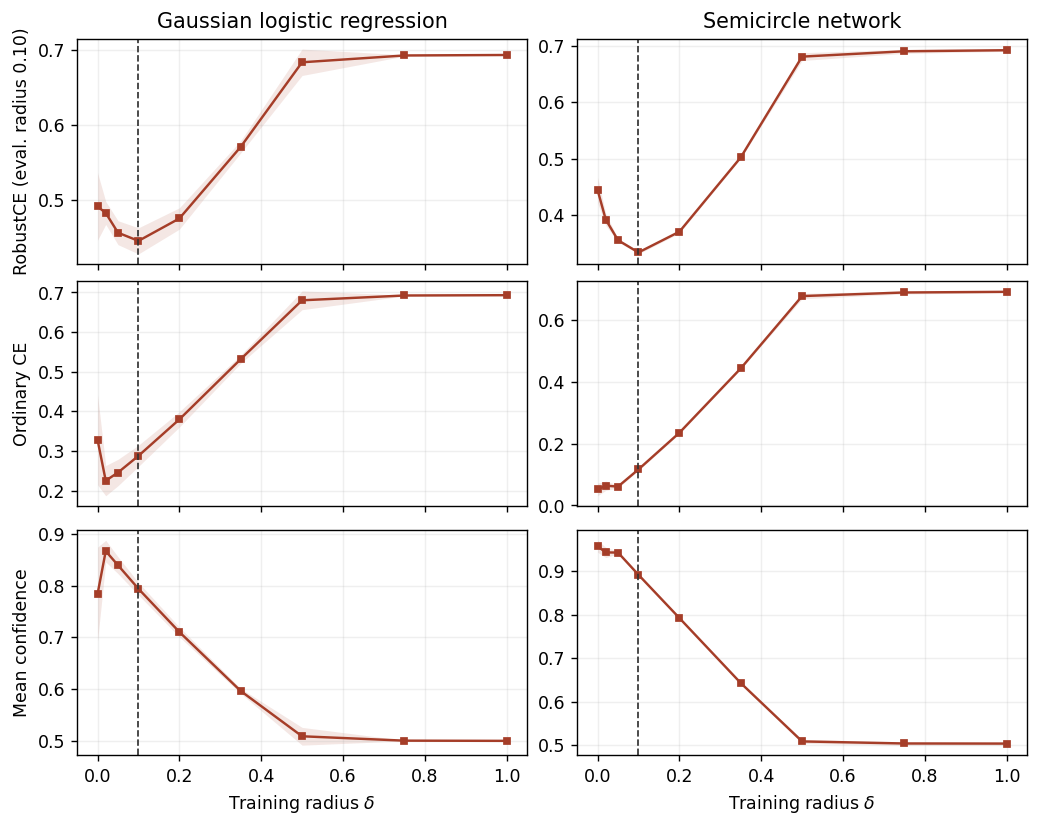

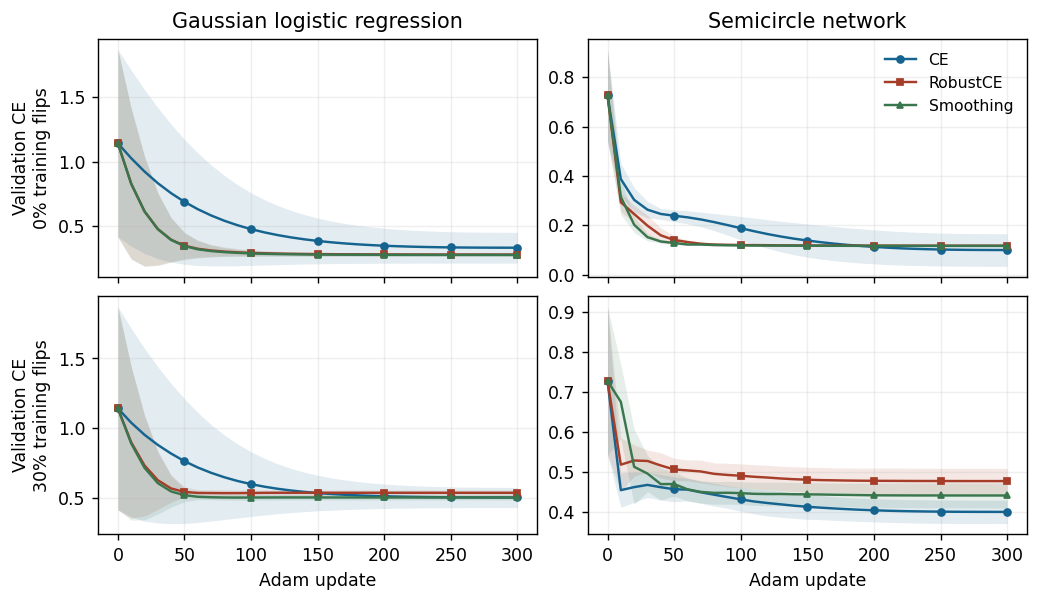

In [10]:
def display_figure(figure, name):
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=125, bbox_inches="tight")
        display(Image(data=buffer.getvalue(), alt=name))
    reporting.plt.close(figure)

with patch.object(reporting, "save", display_figure):
    reporting.selection_plot(tuning, protocol)
    reporting.learning_plot(learning, protocol)

### Decision boundaries

The two figures show clean and 30% flip conditions for seed 201.
The black contour marks a predicted class-1 probability of 0.5.

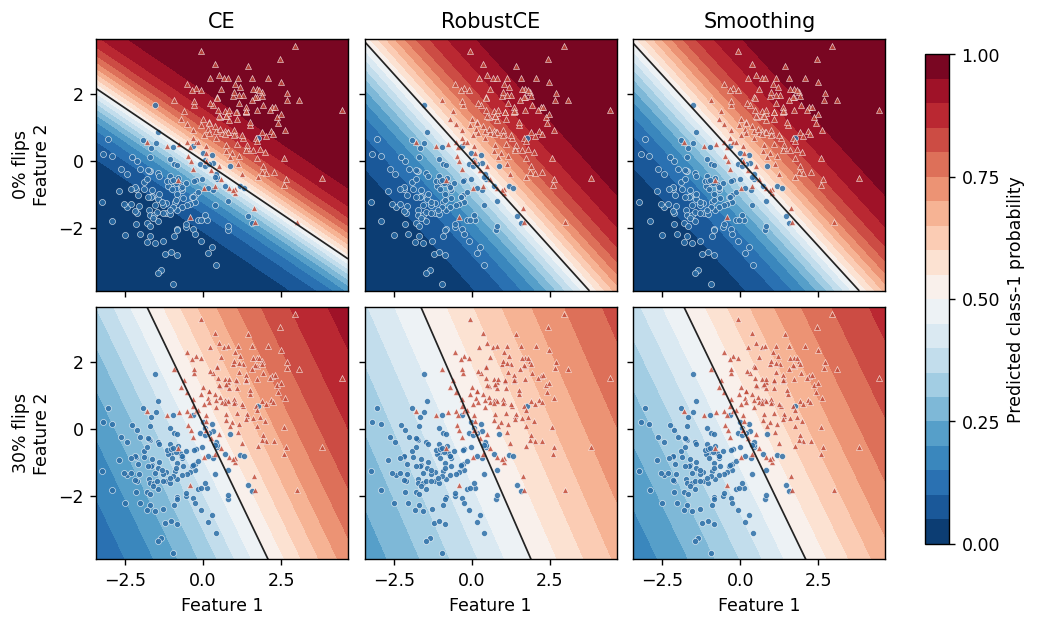

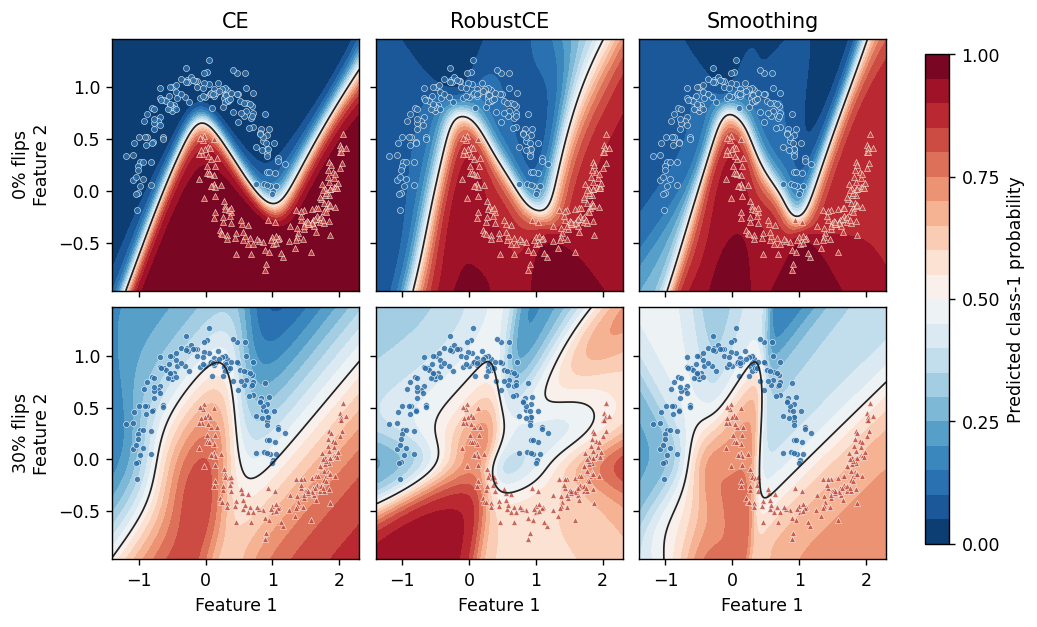

In [11]:
with np.load(result_dir / "representative.npz") as representative:
    with patch.object(reporting, "save", display_figure):
        for simulation in exp.SIMULATIONS:
            reporting.boundary_plot(simulation, protocol, representative)

### Held-out performance under corruption

All plotted scores use clean test labels. Robust test CE uses the same
evaluation radius in every panel.

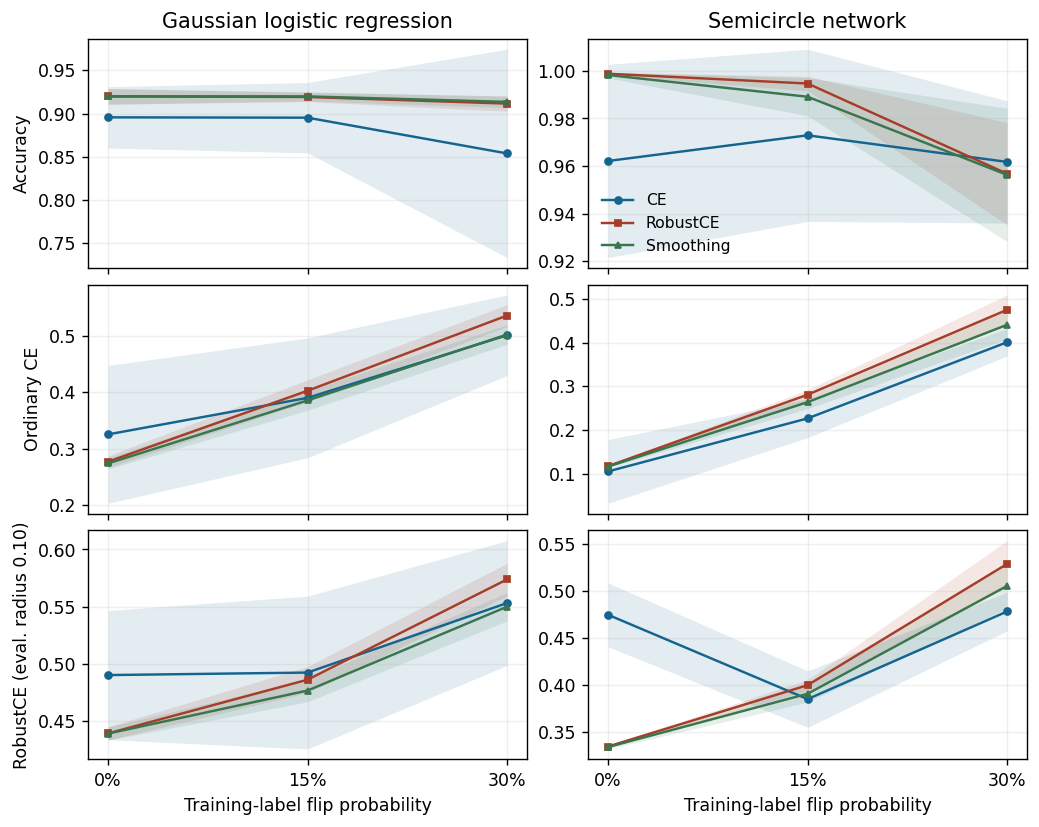

In [12]:
with patch.object(reporting, "save", display_figure):
    reporting.corruption_plot(testing, protocol)

## 7. Read the main result

Use the paired intervals above to judge variability. The table below extracts
the clean and 30% flip contrasts for RobustCE versus CE.

In [13]:
takeaways = []
for simulation in exp.SIMULATIONS:
    for eta in (0.0, protocol["corruption"][-1]):
        condition = reporting.subset(testing, simulation=simulation, eta=eta)
        r = {row["seed"]: row for row in reporting.subset(condition, method="RobustCE")}
        c = {row["seed"]: row for row in reporting.subset(condition, method="CE")}
        takeaways.append([simulation, f"{eta:.0%}",
                          *(paired_interval(r, c, metric) for metric in reporting.METRICS)])
show_table(["Simulation", "Flips", "Accuracy difference (pp)",
            "CE difference", "RobustCE difference"], takeaways)

| Simulation | Flips | Accuracy difference (pp) | CE difference | RobustCE difference |
| --- | --- | --- | --- | --- |
| gaussian | 0% | +2.42 [+0.19, +4.65] | -0.0484 [-0.1305, +0.0337] | -0.0509 [-0.0903, -0.0116] |
| gaussian | 30% | +5.76 [-2.94, +14.45] | +0.0349 [-0.0188, +0.0886] | +0.0206 [-0.0205, +0.0618] |
| semicircles | 0% | +3.67 [+0.75, +6.59] | +0.0122 [-0.0398, +0.0641] | -0.1398 [-0.1636, -0.1161] |
| semicircles | 30% | -0.50 [-3.08, +2.09] | +0.0743 [+0.0602, +0.0884] | +0.0505 [+0.0396, +0.0614] |

Clean-label RobustCE improved common-radius test loss in both simulations.
At 30% flips, it increased both test losses on semicircles. Clean selection
used the robust metric, so these contrasts describe the selected training
settings under that criterion.